# RetinaNet: matching IoU thresholds 0.4 / 0.3 (one-stage anchor-based, tuned)

## Overview

This notebook changes one thing against its parent run `retinanet-rerun` (`draklowell`, current protocol): the IoU thresholds with which RetinaNet's `Matcher` labels anchors. In the parent, an anchor is a positive sample when its IoU with a GT box is at least `fg_iou_thresh = 0.5` and a negative sample below `bg_iou_thresh = 0.4`. Here they are `fg_iou_thresh = 0.4` and `bg_iou_thresh = 0.3`.

**The one change.**
- Parameter: `fg_iou_thresh` / `bg_iou_thresh` of `retinanet_resnet50_fpn_v2`, passed through to torchvision's `RetinaNet` and its `det_utils.Matcher`.
- Range: {0.5 / 0.4 (parent), 0.4 / 0.3}.
- Not changed: everything else of the parent (COCO weights, 9 default anchors per location with base sizes 32 to 512 px, 1,280 px input, 12 epochs, batch 4, SGD with learning rate 0.005, GIoU box loss, focal loss with gamma 2, NMS at 0.5, top 1,000 candidates per level). The anchor count is unchanged, so the pretrained `bbox_reg` weights load as in the parent and there is no forced side change.

**Why.** In the legacy run `retinanet`, 47.0 % of the small objects had an anchor at IoU >= 0.5 and the median best anchor IoU of small objects was 0.487 (EDA notebook `notebooks/eda.ipynb`, §3.2, and `EXPERIMENTS.md`), so more than half of the small objects had no anchor at IoU >= 0.5. On the training frames of the parent, the share of small objects with a best anchor at IoU >= 0.5 is 0.1866 (medium 0.8775, large 0.9983), and the parent reaches `AP_small` 0.0757 (`EXPERIMENTS.md`). A lower foreground threshold gives more of these objects a positive anchor without changing the anchors themselves.

**Expectation.** More small and medium GT boxes get at least one positive anchor, so recall and `AP_small` may rise. The risk is that lower thresholds also add positives with a low IoU, and these teach the box regression from poorly overlapping anchors. In the k-means anchor run `retinanet-kmeans-anchors`, higher anchor coverage and higher recall came with a lower AP75 / AP50 ratio (0.19 against 0.47 for the parent) and a lower `AP_small` (0.0636 against 0.0757; `EXPERIMENTS.md`). This notebook therefore reports the AP75 / AP50 ratio next to the parent's, to see whether the looser matching shifts precision towards low IoU in the same way.

**Comparison with the parent.** The parent already ran under the current protocol, so the difference between the two runs is the matching thresholds and nothing else besides run-to-run noise.

**Extra outputs of this run.** Besides the standard outputs it writes `per_clip_ap.csv`, `size_breakdown.csv`, `final_recall.csv` and `anchor_coverage.csv` (the default anchors on the training frames, the share of GT boxes whose best anchor reaches IoU 0.5 and 0.4). The AP75 / AP50 ratio of this run is shown next to the parent's in the summary table and written to `result.json`.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the matcher labels anchors**

RetinaNet (Lin et al., arXiv:1708.02002) predicts, for every anchor, a class score and a box offset. Before the loss, torchvision's `det_utils.Matcher` assigns each anchor to a GT box by IoU: an anchor with an IoU of at least `fg_iou_thresh` to its best GT box is a positive sample, an anchor below `bg_iou_thresh` is a negative sample, and an anchor in between is ignored in the loss. RetinaNet constructs the matcher with `allow_low_quality_matches=True`, so the anchor with the highest IoU for each GT box is also made positive, whatever its IoU. Positive anchors receive the box regression loss and their class target, all other labelled anchors are background in the focal loss. The thresholds therefore decide how many anchors per GT box train as foreground and how well they must overlap the box. The remaining mechanism of the family (FPN levels P3 to P7, shared heads, focal loss, anchors) is described in `retinanet-rerun`; adaptive per-GT thresholds are the idea of ATSS (arXiv:1912.02424), which this run does not implement.

Requires: Kaggle GPU T4, Internet on.

## Setup

torchvision notebooks install nothing: torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
import contextlib
import io
import json
import math
import platform
import random
import time
from datetime import UTC, datetime
from functools import partial
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader, Dataset

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.io import ImageReadMode, decode_image
from torchvision.models.detection import RetinaNet, RetinaNet_ResNet50_FPN_V2_Weights, retinanet_resnet50_fpn_v2
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import box_iou

Seeding helper, CUDA requirement and the version banner.

In [2]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required: enable the Kaggle T4 accelerator")

started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0)
package_versions = {
    "python": platform.python_version(),
    **{name: version(name) for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib"]},
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | GPU: Tesla T4


## Config

Deviations from torchvision defaults, with reasons:
- `IMAGE_SIZE = 1280` for both `min_size` and `max_size`: objects are often 10–30 px, and the default 800 px would shrink them further.
- `CONF_THRESHOLD = 0.001` and `MAX_DETECTIONS = 500` replace the defaults 0.05 and 300, so COCOeval at 500 detections sees the full score range.
- `LEARNING_RATE = 0.005`: the value of the legacy `retinanet` run and of the Faster R-CNN notebooks (0.02 at batch 16 scaled linearly to batch 4), kept so that the protocols match. The torchvision detection reference uses 0.01 at batch 16 for RetinaNet, which is 0.0025 at batch 4.

- `MATCHER_FG_IOU_THRESHOLD = 0.4` and `MATCHER_BG_IOU_THRESHOLD = 0.3`: the one tuned change (parent: 0.5 and 0.4). They are passed to `retinanet_resnet50_fpn_v2` as `fg_iou_thresh` and `bg_iou_thresh`.
- `PARENT_AP50` and `PARENT_AP75`: the parent's val metrics from `EXPERIMENTS.md` (`retinanet-rerun`), used only for the AP75 / AP50 comparison table.

Not changed: the anchors (9 per location, base sizes 32 to 512 px), NMS at 0.5 and the top 1000 candidates per level. Anchor coverage buckets use COCO's 32² / 96² area limits; the anchor coverage thresholds are `ANCHOR_COVERAGE_IOU_THRESHOLDS` and the recall thresholds are 0.5 and 0.7.

In [3]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")

RUN_NAME = "retinanet-iou-thresholds"
MODEL_NAME = "torchvision retinanet_resnet50_fpn_v2, COCO weights, matcher IoU 0.4 / 0.3"
FAMILY = "one_stage_anchor"
VARIANT = "tuned"
PARENT_RUN = "retinanet-rerun"
CHANGED_PARAMS = ["matcher: fg_iou_thresh/bg_iou_thresh 0.5/0.4 -> 0.4/0.3"]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

IMAGE_SIZE = 1280
EPOCHS = 12
BATCH_SIZE = 4
LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
WARMUP_ITERATIONS = 500
WARMUP_START_FACTOR = 0.001
FINAL_LR_FACTOR = 0.01
GRADIENT_CLIP_NORM = 10.0
HORIZONTAL_FLIP_PROBABILITY = 0.5
WORKERS = 4
DEVICE = torch.device("cuda")
SPEED_PROTOCOL = (
    f"perf_counter around model(images) incl. internal resize and NMS, cuda.synchronize, batch {BATCH_SIZE}, "
    "fp32, Tesla T4, all val frames, first batch excluded"
)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2
LOW_IOU_THRESHOLD = 0.5
HIGH_IOU_THRESHOLD = 0.7
ANCHOR_COVERAGE_IOU_THRESHOLDS = [0.5, 0.4]

MATCHER_FG_IOU_THRESHOLD = 0.4
MATCHER_BG_IOU_THRESHOLD = 0.3
PARENT_AP50 = 0.3814
PARENT_AP75 = 0.1779

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. Training uses every `FRAME_STEP`-th frame of each `train/` clip; consecutive frames are near-duplicates. Validation uses every `val/` frame, and quick validation every `QUICK_VAL_STEP`-th one. The counts are checked against the protocol.

In [4]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded. Ignore boxes come from `ignore/<clip>/<frame>.txt` (normalised centre format); a missing file means the frame has no ignore regions. GT boxes fully inside an ignore box are dropped from training. The fill uses the frame's own per-channel mean, a per-image statistic, so nothing is fitted on validation data.

In [5]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key


def read_ignore_boxes(split: str, frame_key: str, width: int, height: int) -> np.ndarray:
    ignore_path = DATA_ROOT / split / "ignore" / Path(frame_key).with_suffix(".txt")
    if not ignore_path.is_file():
        return np.zeros((0, 4), dtype=np.float32)
    centres = np.array(ignore_path.read_text().split(), dtype=np.float32).reshape(-1, 4)
    centres *= np.array([width, height, width, height], dtype=np.float32)
    half_sizes = centres[:, 2:] / 2
    return np.concatenate([centres[:, :2] - half_sizes, centres[:, :2] + half_sizes], axis=1)


def mask_boxes_inside_regions(boxes: np.ndarray, regions: np.ndarray) -> np.ndarray:
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes), dtype=bool)
    is_inside = (
        (boxes[:, None, 0] >= regions[None, :, 0])
        & (boxes[:, None, 1] >= regions[None, :, 1])
        & (boxes[:, None, 2] <= regions[None, :, 2])
        & (boxes[:, None, 3] <= regions[None, :, 3])
    )
    return is_inside.any(axis=1)


def fill_ignore_regions(image: torch.Tensor, ignore_boxes: np.ndarray) -> torch.Tensor:
    if len(ignore_boxes) == 0:
        return image
    channel_mean = image.float().mean(dim=(1, 2)).round().to(image.dtype)
    height, width = image.shape[-2:]
    filled = image.clone()
    for x1, y1, x2, y2 in np.round(ignore_boxes).astype(int).tolist():
        filled[:, max(y1, 0) : min(y2, height), max(x1, 0) : min(x2, width)] = channel_mean[:, None, None]
    return filled

Apply the helpers: load GT for train and val, read the ignore boxes of the training frames and drop the GT boxes inside them.

In [6]:
train_images, all_train_targets_by_key = load_ground_truth("train")
val_images, val_targets_by_key = load_ground_truth("val")
train_size_by_key = {
    key: (width, height) for key, width, height in train_images.select("frame_key", "width", "height").iter_rows()
}
train_ignore_boxes_by_key = {
    key: read_ignore_boxes("train", key, *train_size_by_key[key]) for key in train_frames["frame_key"]
}
train_targets_by_key = {
    key: all_train_targets_by_key[key][
        ~mask_boxes_inside_regions(all_train_targets_by_key[key][:, :4], train_ignore_boxes_by_key[key])
    ]
    for key in train_frames["frame_key"]
}
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_frames["frame_key"]]
kept_boxes = sum(len(targets) for targets in train_targets_by_key.values())
dropped_boxes = sum(len(all_train_targets_by_key[key]) for key in train_targets_by_key) - kept_boxes
frames_with_ignore = sum(len(boxes) > 0 for boxes in train_ignore_boxes_by_key.values())
print(f"GT kept {kept_boxes} | dropped inside ignore {dropped_boxes} | frames with ignore {frames_with_ignore}")

GT kept 221473 | dropped inside ignore 1406 | frames with ignore 3644


The training loader decodes JPEGs as uint8 in the workers (`decode_image`, typed to return one tensor), fills ignore regions first and then applies the horizontal flip, the only augmentation. Resize and ImageNet normalisation are left to the model's `GeneralizedRCNNTransform`. Labels are `class_id + 1`, because 0 is background in torchvision. Worker seeding follows the PyTorch reproducibility notes. `FramePaths` wraps the path list in a typed `Dataset`, so `DataLoader` gets the type it declares.

In [7]:
class FramePaths(Dataset[str]):
    def __init__(self, paths: list[str]) -> None:
        self.paths = paths

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> str:
        return self.paths[index]


def read_frames(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[str]]:
    return [decode_image(path, mode=ImageReadMode.RGB) for path in frame_paths], frame_paths


def load_training_batch(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[dict[str, torch.Tensor]]]:
    images = []
    targets = []
    for path in frame_paths:
        key = to_frame_key(path)
        image = fill_ignore_regions(decode_image(path, mode=ImageReadMode.RGB), train_ignore_boxes_by_key[key])
        boxes = torch.from_numpy(train_targets_by_key[key][:, :4]).float()
        labels = torch.from_numpy(train_targets_by_key[key][:, 4]).long() + 1
        if random.random() < HORIZONTAL_FLIP_PROBABILITY:
            width = image.shape[-1]
            image = image.flip(-1)
            boxes = torch.stack([width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1)
        images.append(image)
        targets.append({"boxes": boxes, "labels": labels})
    return images, targets


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)


train_loader = DataLoader(
    FramePaths(train_frames["path"].to_list()),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=WORKERS,
    collate_fn=load_training_batch,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    drop_last=True,
    pin_memory=True,
    persistent_workers=True,
)
print(f"{len(train_loader)} steps per epoch")

1217 steps per epoch


Figure helpers: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`, and images are downscaled to at most `FIGURE_IMAGE_MAX_SIDE` px before drawing.

In [8]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)


def downscale_for_display(image: torch.Tensor) -> tuple[np.ndarray, int]:
    stride = math.ceil(max(image.shape[-2:]) / FIGURE_IMAGE_MAX_SIDE)
    return image[:, ::stride, ::stride].permute(1, 2, 0).numpy(), stride

GT visual check: the first training frame with ignore regions, after the mean fill. Green boxes are the kept GT boxes, red dashed boxes are the ignore regions.

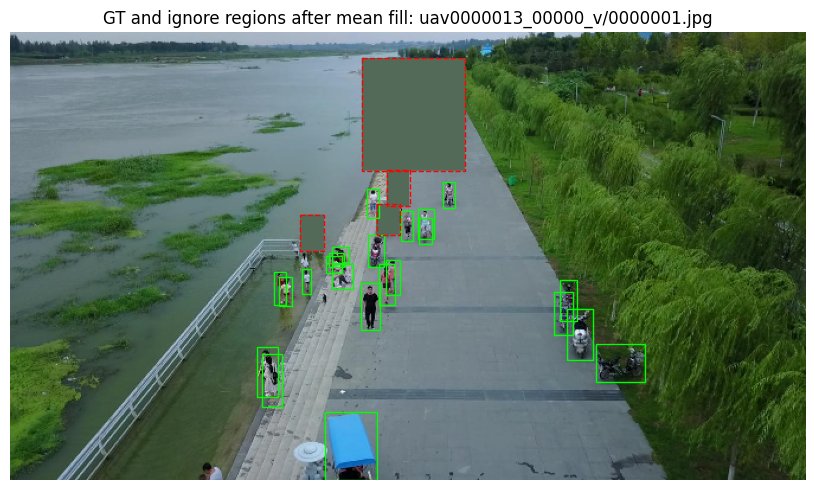

In [9]:
check_key = next(key for key, boxes in train_ignore_boxes_by_key.items() if len(boxes) > 0)
check_path = train_frames.filter(pl.col("frame_key") == check_key)["path"].item()
check_image = fill_ignore_regions(
    decode_image(check_path, mode=ImageReadMode.RGB), train_ignore_boxes_by_key[check_key]
)
display_image, stride = downscale_for_display(check_image)
box_columns = ["x1", "y1", "x2", "y2"]
gt_boxes = pl.DataFrame(train_targets_by_key[check_key][:, :4], schema=box_columns, orient="row")
ignore_boxes = pl.DataFrame(train_ignore_boxes_by_key[check_key], schema=box_columns, orient="row")
drawn_boxes = pl.concat([gt_boxes.with_columns(kind=pl.lit("gt")), ignore_boxes.with_columns(kind=pl.lit("ignore"))])
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.imshow(display_image)
for x1, y1, x2, y2, kind in drawn_boxes.iter_rows():
    is_gt = kind == "gt"
    ax.add_patch(
        Rectangle(
            (x1 / stride, y1 / stride),
            (x2 - x1) / stride,
            (y2 - y1) / stride,
            fill=False,
            edgecolor="lime" if is_gt else "red",
            linestyle="-" if is_gt else "--",
            linewidth=1,
        )
    )
ax.set_title(f"GT and ignore regions after mean fill: {check_key}")
ax.set_xlabel("x (downscaled px)")
ax.set_ylabel("y (downscaled px)")
ax.axis("off")
save_figure(fig, "gt_check", drawn_boxes)

## Model

`retinanet_resnet50_fpn_v2` with COCO weights; `min_size = max_size = IMAGE_SIZE`, score threshold `CONF_THRESHOLD`, `MAX_DETECTIONS` per image. Only the classification head's last layer is replaced: a new `RetinaNetClassificationHead` for 8 classes plus background (index 0 is never a positive label; its detections are dropped at prediction) reuses the pretrained conv tower, and its `cls_logits` layer is initialised afresh with the prior probability 0.01. The regression head keeps its pretrained weights. The one tuned change enters here: `fg_iou_thresh` and `bg_iou_thresh` are `MATCHER_FG_IOU_THRESHOLD` and `MATCHER_BG_IOU_THRESHOLD`, which torchvision hands to the `Matcher` of `RetinaNet`. A forward hook casts the regression head output to float, so that AMP does not degrade the box regression. The type checks make the replacement fail loudly if torchvision changes the head.

In [10]:
def cast_output_to_float(
    module: torch.nn.Module, inputs: tuple[torch.Tensor, ...], output: torch.Tensor
) -> torch.Tensor:
    return output.float()


def build_model() -> RetinaNet:
    model = retinanet_resnet50_fpn_v2(
        weights=RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        score_thresh=CONF_THRESHOLD,
        detections_per_img=MAX_DETECTIONS,
        fg_iou_thresh=MATCHER_FG_IOU_THRESHOLD,
        bg_iou_thresh=MATCHER_BG_IOU_THRESHOLD,
    )
    pretrained_head = model.head.classification_head
    if not isinstance(pretrained_head, RetinaNetClassificationHead):
        raise RuntimeError(f"Unexpected classification head: {type(pretrained_head).__name__}")
    anchors_per_location = model.anchor_generator.num_anchors_per_location()[0]
    classification_head = RetinaNetClassificationHead(
        model.backbone.out_channels,
        anchors_per_location,
        len(CLASSES) + 1,
        norm_layer=partial(torch.nn.GroupNorm, 32),
    )
    classification_head.conv = pretrained_head.conv
    model.head.classification_head = classification_head
    model.head.regression_head.register_forward_hook(cast_output_to_float)
    return model.to(DEVICE)


model = build_model()
parameter_count = sum(parameter.numel() for parameter in model.parameters())
anchor_sizes = [list(level_sizes) for level_sizes in model.anchor_generator.sizes]
print(
    f"retinanet_resnet50_fpn_v2 | {parameter_count / 1e6:.1f} M parameters | {len(CLASSES) + 1} output classes "
    f"| {model.anchor_generator.num_anchors_per_location()[0]} anchors per location "
    f"| matcher IoU {model.proposal_matcher.high_threshold} / {model.proposal_matcher.low_threshold} "
    f"| base anchor sizes per level {anchor_sizes}"
)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 188MB/s]


retinanet_resnet50_fpn_v2 | 36.5 M parameters | 9 output classes | 9 anchors per location | matcher IoU 0.4 / 0.3 | base anchor sizes per level [[32, 40, 50], [64, 80, 101], [128, 161, 203], [256, 322, 406], [512, 645, 812]]


## Training

Optimiser and schedule follow the torchvision detection reference scripts: SGD with momentum 0.9 and weight decay 1e-4, a 500-iteration linear warmup, then cosine decay to 1 % of the base LR. Training uses AMP with gradient clipping at norm 10; batches with a non-finite loss are skipped and counted. BatchNorm statistics in the backbone stay frozen, because batch-4 statistics are too noisy (the `v2` FPN and heads use no BatchNorm).

After every epoch, our COCOeval runs on the quick-val frames, and `best.pt` is overwritten when quick-val mAP@500 improves. After epoch 1 the planned epochs shrink to fit `MAX_TRAIN_HOURS`, and the loop stops when the next epoch would end after the budget.

First, the COCO helpers: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing.

In [11]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [12]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Prediction in fp32 without autocast: fp16 box decoding costs about 1 px, which matters for 10–30 px objects. Boxes are clipped to the image, label 0 (background) is dropped, and labels are converted back to 0-based class ids. Timing follows `SPEED_PROTOCOL`.

In [13]:
def predict_torchvision(model: torch.nn.Module, frame_paths: list[str]) -> tuple[dict[str, FrameDetections], float]:
    loader = DataLoader(
        FramePaths(frame_paths), batch_size=BATCH_SIZE, num_workers=WORKERS, collate_fn=read_frames, pin_memory=True
    )
    model.eval()
    detections_by_key = {}
    inference_seconds = 0.0
    timed_images = 0
    with torch.no_grad():
        for batch_index, (images, batch_paths) in enumerate(loader):
            images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
            torch.cuda.synchronize()
            tick = time.perf_counter()
            outputs = model(images_on_device)
            torch.cuda.synchronize()
            if batch_index > 0:
                inference_seconds += time.perf_counter() - tick
                timed_images += len(images)
            for path, image, output in zip(batch_paths, images, outputs, strict=True):
                height, width = image.shape[-2:]
                is_object = output["labels"] > 0
                boxes = output["boxes"][is_object].float().cpu().numpy()
                boxes = boxes.clip(0, np.array([width, height, width, height], dtype=np.float32))
                scores = output["scores"][is_object].float().cpu().numpy()
                class_ids = (output["labels"][is_object] - 1).cpu().numpy()
                detections_by_key[to_frame_key(path)] = (boxes, scores, class_ids)
    return detections_by_key, 1000 * inference_seconds / timed_images

Optimiser, warmup plus cosine schedule, and BatchNorm freezing. `lr_schedule` holds the total iteration count, so the cosine can be rebuilt when the time guard shortens the run.

In [14]:
def freeze_batch_norm_statistics(module: torch.nn.Module) -> None:
    for layer in module.modules():
        if isinstance(layer, torch.nn.BatchNorm2d):
            layer.eval()


parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(parameters, lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
lr_schedule = {"total_iterations": EPOCHS * len(train_loader)}


def compute_lr_factor(step: int) -> float:
    if step < WARMUP_ITERATIONS:
        return WARMUP_START_FACTOR + (1 - WARMUP_START_FACTOR) * step / WARMUP_ITERATIONS
    decay_iterations = max(lr_schedule["total_iterations"] - WARMUP_ITERATIONS, 1)
    progress = min((step - WARMUP_ITERATIONS) / decay_iterations, 1.0)
    return FINAL_LR_FACTOR + (1 - FINAL_LR_FACTOR) * 0.5 * (1 + math.cos(math.pi * progress))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, compute_lr_factor)

The training loop: one log line per epoch, quick-val COCOeval, best checkpoint, time guard. `history.csv` is rewritten after every epoch, so a crashed session still leaves the log.

In [15]:
scaler = torch.amp.GradScaler("cuda")
history_rows: list[dict[str, float]] = []
skipped_batches = 0
planned_epochs = EPOCHS
training_started = time.time()
epoch = 0
while epoch < planned_epochs:
    epoch += 1
    epoch_started = time.time()
    model.train()
    freeze_batch_norm_statistics(model.backbone)
    loss_sums: dict[str, float] = {}
    steps = 0
    for images, targets in train_loader:
        images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
        targets_on_device = [
            {name: value.to(DEVICE, non_blocking=True) for name, value in target.items()} for target in targets
        ]
        with torch.autocast("cuda", dtype=torch.float16):
            loss_by_name = model(images_on_device, targets_on_device)
            loss = torch.stack(list(loss_by_name.values())).sum()
        if not torch.isfinite(loss):
            skipped_batches += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, GRADIENT_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()
        for name, value in loss_by_name.items():
            loss_sums[name] = loss_sums.get(name, 0.0) + value.item()
        steps += 1

    quick_val_detections, _ = predict_torchvision(model, quick_val_frames["path"].to_list())
    quick_val_evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(quick_val_detections, val_image_id_by_key), quick_val_image_ids
    )
    row = {
        "epoch": epoch,
        **{f"train/{name}": round(total / steps, 4) for name, total in loss_sums.items()},
        "val_mAP": round(compute_map_at_max_detections(quick_val_evaluator), 4),
        "val_AP50": round(float(quick_val_evaluator.stats[1]), 4),
        "lr": optimizer.param_groups[0]["lr"],
        "minutes": round((time.time() - epoch_started) / 60, 1),
    }
    is_best = all(row["val_mAP"] > previous["val_mAP"] for previous in history_rows)
    history_rows.append(row)
    if is_best:
        torch.save(model.state_dict(), OUTPUT_DIR / "best.pt")
    pl.DataFrame(history_rows).write_csv(OUTPUT_DIR / "history.csv")

    elapsed_hours = (time.time() - training_started) / 3600
    if epoch == 1 and int(MAX_TRAIN_HOURS / elapsed_hours) < planned_epochs:
        planned_epochs = max(int(MAX_TRAIN_HOURS / elapsed_hours), 2)
        lr_schedule["total_iterations"] = planned_epochs * len(train_loader)
    print(
        f"epoch {epoch}/{planned_epochs} | {row['minutes']} min | loss {sum(loss_sums.values()) / steps:.3f} "
        f"| quick-val mAP {row['val_mAP']:.4f} | AP50 {row['val_AP50']:.4f}{' | best' if is_best else ''}",
        flush=True,
    )
    if epoch < planned_epochs and elapsed_hours + elapsed_hours / epoch > MAX_TRAIN_HOURS:
        break

train_hours = (time.time() - training_started) / 3600
best_epoch = int(max(history_rows, key=lambda history_row: history_row["val_mAP"])["epoch"])
print(f"training {train_hours:.2f} h | epochs {len(history_rows)} | best {best_epoch} | skipped {skipped_batches}")

epoch 1/12 | 13.2 min | loss 0.586 | quick-val mAP 0.1390 | AP50 0.2537 | best
epoch 2/12 | 13.2 min | loss 0.394 | quick-val mAP 0.1477 | AP50 0.2746 | best
epoch 3/12 | 13.3 min | loss 0.363 | quick-val mAP 0.1488 | AP50 0.2788 | best
epoch 4/12 | 13.3 min | loss 0.341 | quick-val mAP 0.1497 | AP50 0.2834 | best
epoch 5/12 | 13.3 min | loss 0.326 | quick-val mAP 0.1590 | AP50 0.2994 | best
epoch 6/12 | 13.3 min | loss 0.313 | quick-val mAP 0.1601 | AP50 0.3049 | best
epoch 7/12 | 13.3 min | loss 0.303 | quick-val mAP 0.1594 | AP50 0.2988
epoch 8/12 | 13.4 min | loss 0.295 | quick-val mAP 0.1576 | AP50 0.2953
epoch 9/12 | 13.3 min | loss 0.289 | quick-val mAP 0.1558 | AP50 0.2943
epoch 10/12 | 13.3 min | loss 0.285 | quick-val mAP 0.1588 | AP50 0.3004
epoch 11/12 | 13.3 min | loss 0.282 | quick-val mAP 0.1579 | AP50 0.2982
epoch 12/12 | 13.3 min | loss 0.281 | quick-val mAP 0.1581 | AP50 0.2984
training 2.66 h | epochs 12 | best 6 | skipped 0


Training curves: the two RetinaNet loss components per epoch (`classification`, the focal loss over all anchors, and `bbox_regression`, the GIoU loss of the positive anchors) and the quick-val metrics.

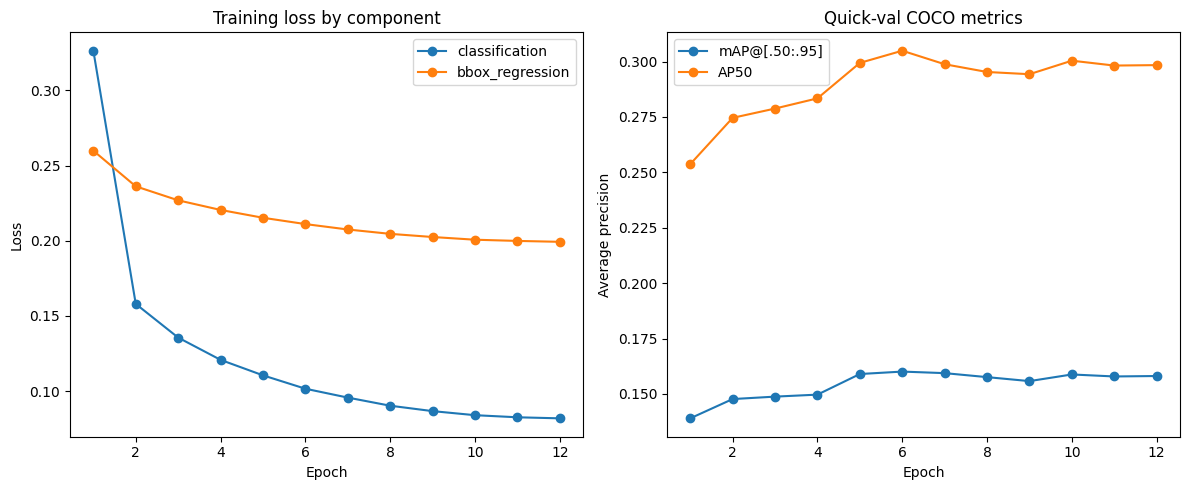

In [16]:
history = pl.DataFrame(history_rows)
loss_columns = [name for name in history.columns if name.startswith("train/")]
fig, (loss_ax, metric_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
for column in loss_columns:
    loss_ax.plot(history["epoch"], history[column], marker="o", label=column.removeprefix("train/"))
loss_ax.set_title("Training loss by component")
loss_ax.set_xlabel("Epoch")
loss_ax.set_ylabel("Loss")
loss_ax.legend()
metric_ax.plot(history["epoch"], history["val_mAP"], marker="o", label="mAP@[.50:.95]")
metric_ax.plot(history["epoch"], history["val_AP50"], marker="o", label="AP50")
metric_ax.set_title("Quick-val COCO metrics")
metric_ax.set_xlabel("Epoch")
metric_ax.set_ylabel("Average precision")
metric_ax.legend()
save_figure(fig, "training_curves", history)

## Validation

The best checkpoint by quick-val mAP@500 is evaluated on all val frames. Quick val is a subset of val, so this score is slightly optimistic. Speed protocol: `perf_counter` around `model(images)` including the internal resize and NMS, with `cuda.synchronize`, batch `BATCH_SIZE`, fp32, Tesla T4, all val frames, first batch excluded.

In [17]:
model.load_state_dict(torch.load(OUTPUT_DIR / "best.pt", map_location=DEVICE, weights_only=True))
val_detections_by_key, ms_per_image = predict_torchvision(model, val_frames["path"].to_list())
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} | {ms_per_image:.1f} ms/image")

1412715 detections | mAP 0.1596 | 180.1 ms/image


`result.json` writer: the core keys are checked before writing.

In [18]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without `versions` and `changed_params`).

In [19]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": IMAGE_SIZE,
    "epochs_planned": EPOCHS,
    "epochs_run": len(history_rows),
    "best_epoch": best_epoch,
    "batch": BATCH_SIZE,
    "lr": LEARNING_RATE,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "AP75_over_AP50": round(val_metrics["AP75"] / val_metrics["AP50"], 4),
    "parent_AP75_over_AP50": round(PARENT_AP75 / PARENT_AP50, 4),
    "matcher_fg_iou_thresh": MATCHER_FG_IOU_THRESHOLD,
    "matcher_bg_iou_thresh": MATCHER_BG_IOU_THRESHOLD,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(train_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if key not in ("versions", "changed_params")}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,AP75_over_AP50,parent_AP75_over_AP50,matcher_fg_iou_thresh,matcher_bg_iou_thresh,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at
str,str,str,str,str,str,i64,i64,i64,i64,i64,i64,f64,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""retinanet-iou-thresholds""","""new-notebooks/retinanet-iou-th…","""torchvision retinanet_resnet50…","""one_stage_anchor""","""tuned""","""retinanet-rerun""",42,1280,12,12,6,4,0.005,4868,2846,5,"""per_image_mean_fill""",0.1596,0.1596,0.3033,0.1489,0.0497,0.1294,0.3264,0.2565,0.4909,0.4664,0.4,0.3,180.1,"""perf_counter around model(imag…",2.66,"""Tesla T4""","""2026-11-02T23:46:22+00:00""","""2026-11-03T02:42:04+00:00"""


AP75 / AP50 next to the parent. The question: does the share of AP at IoU 0.75 relative to AP at IoU 0.5 differ between this run and the parent `retinanet-rerun`? How to read this table: one row per run; `AP50` and `AP75` are AP at IoU 0.5 and 0.75 at 500 detections per frame, `AP75_over_AP50` is their ratio. The parent's values are the constants `PARENT_AP50` and `PARENT_AP75` from `EXPERIMENTS.md`. Written to `ap_ratio.csv`.

In [20]:
ap_ratio = pl.DataFrame(
    {
        "run": [RUN_NAME, "retinanet-rerun"],
        "AP50": [val_metrics["AP50"], PARENT_AP50],
        "AP75": [val_metrics["AP75"], PARENT_AP75],
    }
).with_columns(AP75_over_AP50=(pl.col("AP75") / pl.col("AP50")).round(4))
ap_ratio.write_csv(OUTPUT_DIR / "ap_ratio.csv")
ap_ratio

run,AP50,AP75,AP75_over_AP50
str,f64,f64,f64
"""retinanet-iou-thresholds""",0.3033,0.1489,0.4909
"""retinanet-rerun""",0.3814,0.1779,0.4664


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [21]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.199,0.4774
1,"""bicycle""",0.0844,0.178
2,"""car""",0.3088,0.5115
3,"""van""",0.2178,0.3402
4,"""truck""",0.2598,0.4486
5,"""tricycle""",0.1587,0.3412
6,"""bus""",0.0031,0.0047
7,"""motor""",0.045,0.1251


Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the full-val detections are filtered to the clip's frames and evaluated against the same ground truth. How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [22]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


per_clip_ap = build_per_clip_ap(val_predictions)
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.1433,0.4027,0.1283
"""uav0000117_02622_v""",349,0.245,0.4788,0.0
"""uav0000137_00458_v""",233,0.1559,0.301,0.0
"""uav0000182_00000_v""",363,0.1199,0.2587,0.0577
"""uav0000268_05773_v""",978,0.1084,0.1514,0.0062
"""uav0000305_00000_v""",184,0.1858,0.2639,0.0001
"""uav0000339_00001_v""",275,0.2262,0.3682,0.0368


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [23]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.1596,0.3033,0.2565,0.4295
"""small""",21910,0.0497,0.1448,0.0955,0.219
"""medium""",79357,0.1294,0.2624,0.2089,0.3692
"""large""",12865,0.3264,0.5506,0.4914,0.7531


Anchor coverage. The question: how many training GT boxes have at least one default anchor with IoU >= 0.5 and >= 0.4 (the foreground thresholds of the parent and of this run), and how good is the best anchor? Anchors depend only on the image size and the feature map shapes, not on the weights, so they are generated once per distinct frame size by running `model.transform` and the backbone on a blank frame of that size. Each frame's GT boxes (the 4,868 training frames, after dropping the boxes inside ignore regions) are scaled to the resized frame and matched against all anchors of that size. The matcher also makes each GT box's best anchor positive whatever its IoU (`allow_low_quality_matches=True`), so these shares count boxes whose best anchor reaches the threshold by IoU alone. The code adapts the anchor-coverage cell of the legacy `retinanet`, which used the quick-val frames. How to read this table: one row per size bucket (COCO buckets in original pixels, `all` is the total). `anchor_coverage_50` and `anchor_coverage_40` are the shares of GT boxes whose best anchor has IoU >= 0.5 and >= 0.4, and `median_best_anchor_iou` is the median of that best IoU. Written to `anchor_coverage.csv`.

In [24]:
def group_by_size_bucket(measurements: pl.DataFrame, aggregations: list[pl.Expr]) -> pl.DataFrame:
    sized = measurements.with_columns(
        size=pl.when(pl.col("area") < SMALL_AREA)
        .then(pl.lit("small"))
        .when(pl.col("area") < MEDIUM_AREA)
        .then(pl.lit("medium"))
        .otherwise(pl.lit("large"))
    )
    return (
        pl.concat([sized, sized.with_columns(size=pl.lit("all"))])
        .group_by("size")
        .agg(pl.len().alias("objects"), *aggregations)
        .sort(pl.col("size").replace_strict({"all": 0, "small": 1, "medium": 2, "large": 3}))
    )


def generate_anchors_for_frame_size(model: RetinaNet, width: int, height: int) -> tuple[torch.Tensor, torch.Tensor]:
    blank_frame = torch.zeros(3, height, width, device=DEVICE)
    image_list, _ = model.transform([blank_frame])
    features = list(model.backbone(image_list.tensors).values())
    anchors = model.anchor_generator(image_list, features)[0]
    resized_height, resized_width = image_list.image_sizes[0]
    scale = torch.tensor([resized_width / width, resized_height / height] * 2, device=DEVICE)
    return anchors, scale


def measure_best_anchor_ious(model: RetinaNet) -> pl.DataFrame:
    model.eval()
    train_keys = train_frames["frame_key"].to_list()
    frame_keys_by_size = (
        train_images.filter(pl.col("frame_key").is_in(train_keys)).group_by("width", "height").agg("frame_key")
    )
    areas = []
    best_ious = []
    with torch.no_grad():
        for width, height, frame_keys in frame_keys_by_size.iter_rows():
            anchors, scale = generate_anchors_for_frame_size(model, width, height)
            for key in frame_keys:
                boxes = train_targets_by_key[key][:, :4]
                if len(boxes) == 0:
                    continue
                areas.append((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]))
                scaled_boxes = torch.from_numpy(boxes).to(DEVICE) * scale
                best_ious.append(torch.amax(box_iou(scaled_boxes, anchors), dim=1).cpu().numpy())
    return pl.DataFrame({"area": np.concatenate(areas), "best_anchor_iou": np.concatenate(best_ious)})


best_anchor_ious = measure_best_anchor_ious(model)
anchor_coverage = group_by_size_bucket(
    best_anchor_ious,
    [
        *[
            (pl.col("best_anchor_iou") >= threshold).mean().round(4).alias(f"anchor_coverage_{round(threshold * 100)}")
            for threshold in ANCHOR_COVERAGE_IOU_THRESHOLDS
        ],
        pl.col("best_anchor_iou").median().round(4).alias("median_best_anchor_iou"),
    ],
)
anchor_coverage.write_csv(OUTPUT_DIR / "anchor_coverage.csv")
anchor_coverage

size,objects,anchor_coverage_50,anchor_coverage_40,median_best_anchor_iou
str,u32,f64,f64,f32
"""all""",221473,0.7204,0.7942,0.6968
"""small""",54879,0.1866,0.3227,0.3135
"""medium""",140833,0.8775,0.9404,0.7229
"""large""",25761,0.9983,0.9998,0.7685


Final recall by size. The question: how many val GT boxes are covered by a final detection? For every non-crowd GT box of all val frames, the best IoU over all final detections of the frame (any class, up to 500 per frame, score ≥ 0.001, taken from the full-val predictions) is computed. This is class-agnostic and differs from the COCOeval `recall50` of `size_breakdown.csv`, which also requires the right class. How to read this table: one row per size bucket (`all` is the total). `final_recall_50` and `final_recall_70` are the shares of GT boxes with a detection at IoU ≥ 0.5 and ≥ 0.7. Written to `final_recall.csv`.

In [25]:
def compute_best_ious(gt_boxes: np.ndarray, candidate_boxes: np.ndarray) -> np.ndarray:
    if len(gt_boxes) == 0 or len(candidate_boxes) == 0:
        return np.zeros(len(gt_boxes), dtype=np.float32)
    return torch.amax(box_iou(torch.from_numpy(gt_boxes), torch.from_numpy(candidate_boxes)), dim=1).numpy()


val_areas = []
final_ious = []
for key, targets in val_targets_by_key.items():
    gt_boxes = targets[:, :4]
    val_areas.append((gt_boxes[:, 2] - gt_boxes[:, 0]) * (gt_boxes[:, 3] - gt_boxes[:, 1]))
    final_ious.append(compute_best_ious(gt_boxes, val_detections_by_key[key][0]))
final_recall = group_by_size_bucket(
    pl.DataFrame({"area": np.concatenate(val_areas), "final_iou": np.concatenate(final_ious)}),
    [
        (pl.col("final_iou") >= LOW_IOU_THRESHOLD).mean().round(4).alias("final_recall_50"),
        (pl.col("final_iou") >= HIGH_IOU_THRESHOLD).mean().round(4).alias("final_recall_70"),
    ],
)
final_recall.write_csv(OUTPUT_DIR / "final_recall.csv")
final_recall

size,objects,final_recall_50,final_recall_70
str,u32,f64,f64
"""all""",114132,0.5535,0.3739
"""small""",21910,0.3408,0.1344
"""medium""",79357,0.5481,0.3631
"""large""",12865,0.9491,0.8483


## Submission

Predict every test frame with the best checkpoint and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections.

In [26]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_images = pl.read_csv(DATA_ROOT / "test_images.csv")
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_detections_by_key, _ = predict_torchvision(
    model, [str(DATA_ROOT / file_name) for file_name in test_images["file_name"]]
)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[to_frame_key(file_name)])
    for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed column names `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [27]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Lin, Goyal, Girshick, He, Dollár. Focal Loss for Dense Object Detection (RetinaNet). arXiv:1708.02002.
- Lin, Dollár, Girshick, He, Hariharan, Belongie. Feature Pyramid Networks for Object Detection. arXiv:1612.03144.
- Zhang, Chi, Yao, Lei, Li. Bridging the Gap Between Anchor-based and Anchor-free Detection via Adaptive Training Sample Selection (ATSS; the reference of torchvision's `retinanet_resnet50_fpn_v2`). arXiv:1912.02424.
- Rezatofighi, Tsoi, Gwak, Sadeghian, Reid, Savarese. Generalized Intersection over Union (GIoU loss of the `v2` regression head). arXiv:1902.09630.
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- torchvision `retinanet_resnet50_fpn_v2`, its `RetinaNetClassificationHead` and the detection reference scripts (optimiser, warmup, LR scaling), BSD-3-Clause: https://github.com/pytorch/vision/tree/main/references/detection
- torchvision `v2` RetinaNet training recipe: https://github.com/pytorch/vision/pull/5756
- torchvision RetinaNet model documentation: https://pytorch.org/vision/stable/models/retinanet.html
- torchvision `RetinaNet` (`fg_iou_thresh`, `bg_iou_thresh`) and `det_utils.Matcher`, BSD-3-Clause: https://github.com/pytorch/vision/blob/main/torchvision/models/detection/_utils.py
- PyTorch reproducibility notes (`seed_worker`, seeded generator): https://pytorch.org/docs/stable/notes/randomness.html
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§3.2 anchors and sizes): source of the object-size numbers in the Overview.
- Legacy run `retinanet` (`notebooks/draklowell/retinanet.ipynb`, report `experiments/draklowell/retinanet.md`, `EXPERIMENTS.md`): source of the model construction (new classification head on the pretrained conv tower, float-cast hook), the protocol example and the anchor-coverage cell that `anchor_coverage.csv` adapts.
- Faster R-CNN notebooks `faster-rcnn-template` and `faster-rcnn-small-anchors` of this repository: source of the protocol code.
- Parent run `retinanet-rerun` (`new-notebooks/retinanet-rerun.ipynb`, `draklowell`): source of all protocol and model code that this notebook copies, and of the parent numbers in the Overview.
- Run `retinanet-kmeans-anchors` (`new-notebooks/retinanet-kmeans-anchors.ipynb`): source of the submission checks without `sample_submission.csv`, and of the AP75 / AP50 observation in the Overview (`EXPERIMENTS.md`).